In [1]:
# Exercise 4: E-Commerce Text & Quantitative Analytics

In [1]:
%pip install wordcloud

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
import re

In [4]:
# Load dataset
df = pd.read_csv('flipkart_product.csv', encoding="latin1")

# Display first five records
df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",1,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,"??3,999",3,Fair,Ok ok product


In [5]:
# Dataset information
df.info()

# Check missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 189874 entries, 0 to 189873
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   ProductName  189874 non-null  object
 1   Price        189873 non-null  object
 2   Rate         189873 non-null  object
 3   Review       189870 non-null  object
 4   Summary      189860 non-null  object
dtypes: object(5)
memory usage: 7.2+ MB


ProductName     0
Price           1
Rate            1
Review          4
Summary        14
dtype: int64

In [7]:
# Clean rating column
df['Rate'] = pd.to_numeric(
    df['Rate'].astype(str).str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Clean price column
df['Price'] = pd.to_numeric(
    df['Price'].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce'
)

# Remove records with missing important values
df = df.dropna(subset=['ProductName', 'Rate', 'Price'])

# Display cleaned data
df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,3999.0,5.0,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,3999.0,5.0,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,3999.0,3.0,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,3999.0,1.0,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?ÿ?ÿ(White...,3999.0,3.0,Fair,Ok ok product


In [8]:
# Group by product name and calculate mean rating and price
items = df.groupby('ProductName').agg({
    'Rate': 'mean',
    'Price': 'mean'
}).reset_index()

# Display summary table
print(items.head(10))

                                         ProductName      Rate    Price
0  1170-BL-BR Unique New Day & Date Analog Watch ...  3.986667    299.0
1      38024PP25 Minimalists Analog Watch  - For Men  4.888889    850.0
2  3D METRO SUPER STORE JUICER_Gduumy 1 Juicer,1 ...  3.670000    417.0
3  3D METRO SUPER STORE METRO_MIXER Pro 0 Juicer ...  4.750000    199.0
4             77085PP03 Volt Analog Watch  - For Men  4.711111    699.0
5  7SEVEN Airtel DTH Remote Airtel Xstream Remote...  4.687500    219.0
6  @Home by nilkamal Walton Engineered Wood TV En...  4.444444  11999.0
7   ADONYX Combo of Knee,Palm, Elbow & Ankle Support  3.803571    199.0
8  ADZOY Metal Lazy Stand Bracket for Neck Rest o...  3.516129    284.0
9  AGAMI Green 2 Layer Lucky Bamboo plant with Bi...  4.455000    279.0


In [9]:
items.to_csv('product_summary.csv', index=False)

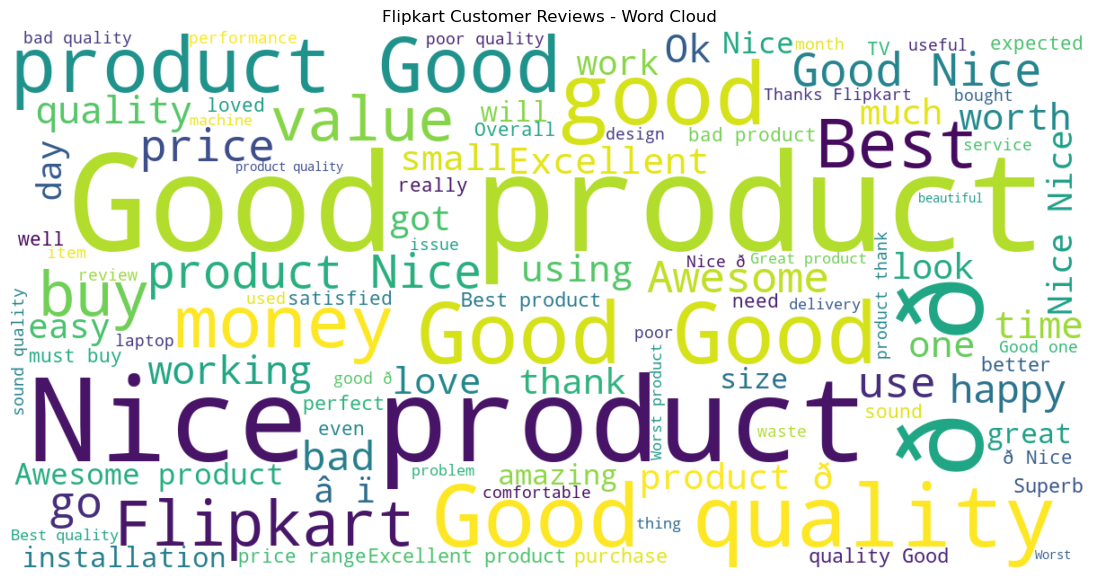

In [10]:
# Combine all customer review summaries
text = ' '.join(df['Summary'].dropna().astype(str))

# Generate Word Cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    stopwords=STOPWORDS,
    max_words=100,
    colormap='viridis'
).generate(text)

# Display Word Cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Flipkart Customer Reviews - Word Cloud')
plt.show()